# **Dimention Reduction**

<font color='#FF15D'> **Task1:**


Use **PCA** to reduce the dataset to 3 dimensions and visualize the results.

Steps:

Standardize the dataset (excluding the Character column).

Apply PCA with n_components=3.

Create a 3D scatter plot of the transformed data.

Add labels (character names) to each point in the plot.

<font color='#FF15D'>**Task2:**


Re-use the same dataset, but this time apply **t-SNE** for dimensionality reduction and visualization.

Steps:

Standardize the dataset (exclude the Character column).

Apply t-SNE with n_components=2 (or 3).

Create a scatter plot of the transformed data.

Label each point with the character name.

## Task 1: PCA

In [32]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [3]:
# Data
data = {
    'Character': ['ShadowFang', 'IronTusk', 'Arcana', 'ThunderBlaze', 'PhantomStrike', 'BruteHammer'],
    'Speed' : [8,3,4,6,7,2],
    'Strength' : [7,9,2,6,4,10],
    'Defense' : [5,8,3,6,4,9],
    'Magic' : [2,1,9,3,4,1],
    'Range' : [6,4,8,5,9,3],
    'Agility' : [9,2,5,6,8,1]
}
df = pd.DataFrame(data)

In [4]:
df

,Character,Speed,Strength,Defense,Magic,Range,Agility
0,ShadowFang,8,7,5,2,6,9
1,IronTusk,3,9,8,1,4,2
2,Arcana,4,2,3,9,8,5
3,ThunderBlaze,6,6,6,3,5,6
4,PhantomStrike,7,4,4,4,9,8
5,BruteHammer,2,10,9,1,3,1


In [11]:
# excluding character column
characters = df['Character']
features = df.drop(columns=['Character'])
scaler = StandardScaler()
# .fit_transform() performs 2 operations: fit learns each feature's mean and std, then transform computes z=(value-mean)/std
X_scaled = scaler.fit_transform(X=features)
print("original numeric shape", features.shape)
print("standardized shape: ", X_scaled.shape)

assert features.shape == X_scaled.shape

original numeric shape (6, 6)
standardized shape:  (6, 6)


#### Why standardize?
PCA follows variance. Without scaling, an attribute with a larger spread can dominate the result because of its units or numerical range. Standardization puts these attributes on a comparable scale. It does not make them equally influential in the resulting components.

In [12]:
#Apply PCA with n_components=3.
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X=X_scaled)

X_pca

array([[-0.9018595 ,  1.78798989, -0.26504483],
       [ 2.32398556, -0.21886206,  0.21234754],
       [-2.34745432, -2.05823291, -0.2115821 ],
       [-0.0586734 ,  0.48856823, -0.42093578],
       [-2.21875593,  0.49497493,  0.63607347],
       [ 3.20275757, -0.49443808,  0.04914169]])

In [17]:
#put the new coordidates in a df
pca_df = pd.DataFrame(data=X_pca,columns=['PCA1','PCA2','PCA3'], index=characters)
display(pca_df)

print("Reduced shape: ", X_pca.shape)
#check how much of the standardized data's variance retained
variance_ratio = pca.explained_variance_ratio_
print("Explained variance ratio per component: ", variance_ratio)
print("Total variance retained: ", variance_ratio.sum()) 
#

,PCA1,PCA2,PCA3
Character,,,
ShadowFang,-0.901859,1.787990,-0.265045
IronTusk,2.323986,-0.218862,0.212348
Arcana,-2.347454,-2.058233,-0.211582
ThunderBlaze,-0.058673,0.488568,-0.420936
PhantomStrike,-2.218756,0.494975,0.636073
BruteHammer,3.202758,-0.494438,0.049142


Reduced shape:  (6, 3)
Explained variance ratio per component:  [0.74746605 0.22803609 0.02067496]
Total variance retained:  0.9961770966560592


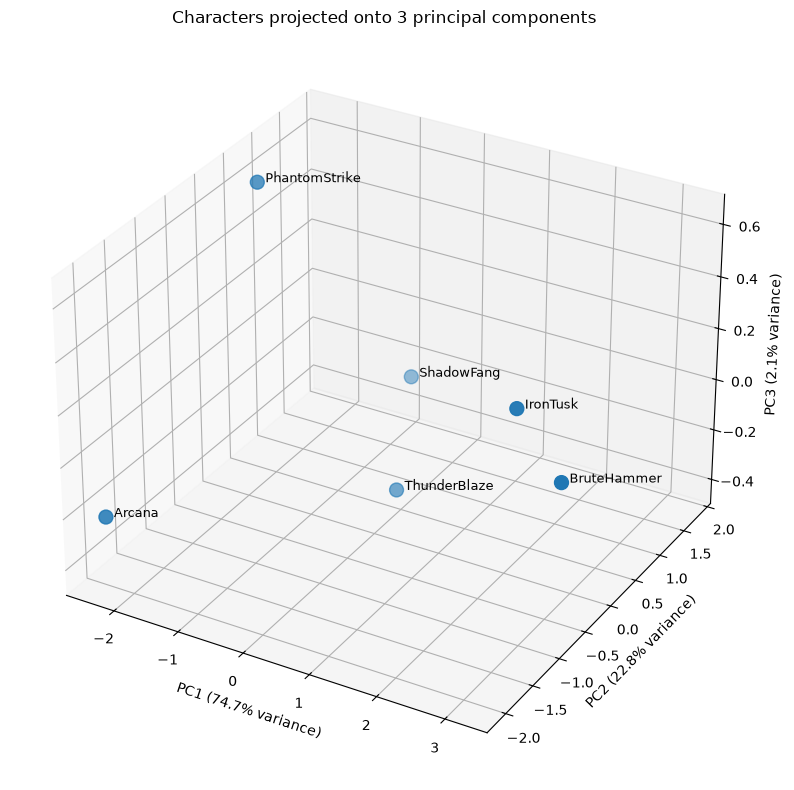

In [27]:
'''Create a 3D scatter plot of the transformed data.

Add labels (character names) to each point in the plot.'''

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(xs=X_pca[:,0], ys=X_pca[:,1], zs =X_pca[:,2],s=100)

for char, (x,y,z) in zip(characters, X_pca):
    ax.text(x=x, y=y, z=z, s="  " + char, fontsize=9)
    

ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%} variance)")
ax.set_zlabel(f"PC3 ({variance_ratio[2]:.1%} variance)")
ax.set_title("Characters projected onto 3 principal components")
plt.tight_layout()
plt.show()

In [29]:
#inspect the weights used to form each component. Large absolute weights show that attributes contributing strongly to that component.
component_weights = pd.DataFrame(
    pca.components_,
    index=["PC1", "PC2", "PC3"],
    columns=features.columns,
)
print(component_weights.round(3))

     Speed  Strength  Defense  Magic  Range  Agility
PC1 -0.329     0.442    0.468 -0.358 -0.449   -0.384
PC2  0.610     0.283    0.085 -0.541 -0.069    0.492
PC3 -0.189     0.070    0.127 -0.436  0.847   -0.188


In [30]:
X_scaled.mean(axis=0), X_scaled.std(axis=0)

(array([ 0.00000000e+00,  1.11022302e-16,  1.85037171e-16, -1.29526020e-16,
         1.48029737e-16, -1.11022302e-16]),
 array([1., 1., 1., 1., 1., 1.]))

In [31]:
df

,Character,Speed,Strength,Defense,Magic,Range,Agility
0,ShadowFang,8,7,5,2,6,9
1,IronTusk,3,9,8,1,4,2
2,Arcana,4,2,3,9,8,5
3,ThunderBlaze,6,6,6,3,5,6
4,PhantomStrike,7,4,4,4,9,8
5,BruteHammer,2,10,9,1,3,1


IronTusk and BruteHammer have similar original profiles. Their projected points are close together

## Task 2: t-SNE

t-SNE converts original-space similarities into probabilities, represents similarities in the output map using a heavy-tailed Student t distribution, and iteratively adjusts the map to reduce a mismatch measured by KL divergence. This is why its final coordinates are learned positions rather than weighted linear combinations like PCA scores.

In [39]:
from sklearn.manifold import TSNE


### Why standardize?
t-SNE uses distances to build similarities. An attribute with a much larger numerical scale can dominate those distances. Scaling puts the attributes on a comparable scale.

In [37]:
tsne = TSNE(n_components=2, perplexity=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled,)

X_tsne

array([[ -33.320637,   45.098644],
       [ 105.7246  , -622.2864  ],
       [-122.51916 ,  498.11096 ],
       [  -6.814781, -132.95428 ],
       [ -73.92079 ,  253.40826 ],
       [ -10.855118, -750.4218  ]], dtype=float32)

In [40]:
tsne_df = pd.DataFrame(data=X_tsne, columns=['t-SNE 1', 't-SNE 2'], index=characters)
display(tsne_df)
print("Reduced shape: ", X_tsne.shape)

,t-SNE 1,t-SNE 2
Character,,
ShadowFang,-33.320637,45.098644
IronTusk,105.724602,-622.286377
Arcana,-122.519157,498.110962
ThunderBlaze,-6.814781,-132.954285
PhantomStrike,-73.920792,253.408264
BruteHammer,-10.855118,-750.421814


Reduced shape:  (6, 2)


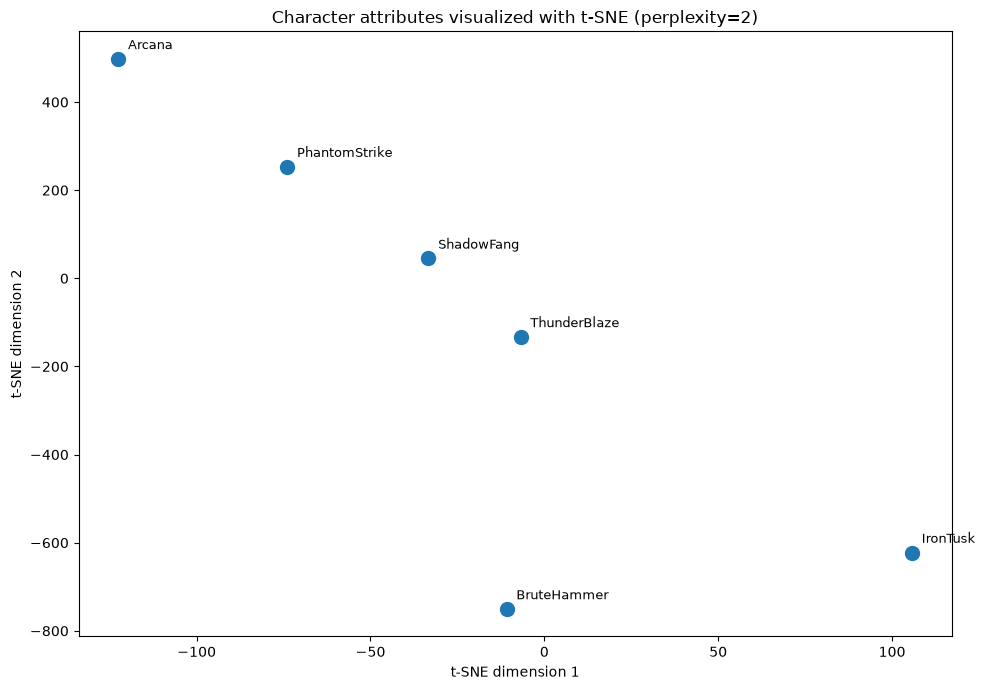

In [43]:
'''Create a scatter plot of the transformed data.

Label each point with the character name.'''

fig, ax = plt.subplots(figsize=(10,7))
ax.scatter(x=X_tsne[:,0], y=X_tsne[:,1], s=100)

for char, (x,y) in zip(characters, X_tsne):
    ax.annotate(text=char, xy=(x,y), xytext=(7,7), textcoords="offset points",fontsize=9,)

ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.set_title("Character attributes visualized with t-SNE (perplexity=2)")
plt.tight_layout()
plt.show()

In [44]:
X_scaled

array([[ 1.38873015,  0.24253563, -0.3940552 , -0.48507125,  0.07881104,
         1.31697617],
       [-0.9258201 ,  0.9701425 ,  1.02454353, -0.84887469, -0.86692145,
        -1.08793684],
       [-0.46291005, -1.57648156, -1.33978769,  2.06155281,  1.02454353,
        -0.05725983],
       [ 0.46291005, -0.12126781,  0.07881104, -0.12126781, -0.3940552 ,
         0.28629917],
       [ 0.9258201 , -0.84887469, -0.86692145,  0.24253563,  1.49740977,
         0.97341717],
       [-1.38873015,  1.33394594,  1.49740977, -0.84887469, -1.33978769,
        -1.43149584]])

Each point is a character. Nearby points suggests a local similarity in the standardized attributes. The embedding is approximate and parameter-dependent. It does not guarantee that everyone original neighbor stays nearby. 

Unlike PCA, t-SNE has no explained_variance_ratio_. It does not maximize retained variance.